<div>

## Parte 2. AAPL, MSFT y NVDA

Aquí vemos cómo generar escenarios **correlacionados**: de la covarianza histórica se obtiene la matriz `L` (Cholesky) y con ella se convierten normales independientes en normales con la correlación de los datos.

</div>

In [15]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


<div>

### 2.1 Datos y matriz de correlación

Descargamos los precios de AAPL, MSFT y NVDA y calculamos la correlación histórica de sus rendimientos diarios porcentuales.

</div>

In [16]:
tickers_corr = ['AAPL', 'MSFT', 'NVDA']
precios_corr = yf.download(tickers_corr, start='2023-11-01', end='2026-11-01')['Close']
correlation_matrix = precios_corr.pct_change().corr()
print(correlation_matrix.round(4))

[*********************100%***********************]  3 of 3 completed

Ticker    AAPL    MSFT    NVDA
Ticker                        
AAPL    1.0000  0.3361  0.2904
MSFT    0.3361  1.0000  0.4226
NVDA    0.2904  0.4226  1.0000


<div>

### 2.2 Matriz de covarianza

Calculamos los rendimientos logarítmicos de AAPL, MSFT y NVDA. `Sigma` es su covarianza anualizada (covarianza diaria × 252) y `media` contiene los rendimientos medios anualizados.

</div>

In [17]:
rendimientos_corr = np.log(precios_corr / precios_corr.shift(1)).dropna()
Sigma = (rendimientos_corr.cov() * 252).to_numpy()
media = (rendimientos_corr.mean() * 252).to_numpy()

print('Matriz de covarianza anualizada:')
print(Sigma)
print('Media anualizada:')
print(media)

Matriz de covarianza anualizada:
[[0.07118952 0.02311266 0.03532503]
 [0.02311266 0.06716451 0.05090355]
 [0.03532503 0.05090355 0.21677921]]
Media anualizada:
[0.23388784 0.14563172 0.52978937]


<div>

### 2.3 Descomposición de Cholesky

Obtenemos la matriz triangular inferior `L` que cumple

$$\Sigma = L \, L^{T}$$

La comprobación `L @ L.T` debe devolver `Sigma`.

</div>

In [18]:
L = np.linalg.cholesky(Sigma)
print(L)
print('Comprobacion L @ L.T:')
print(L @ L.T)

[[0.26681364 0.         0.        ]
 [0.08662474 0.24425532 0.        ]
 [0.1323959  0.16144906 0.4161547 ]]
Comprobacion L @ L.T:
[[0.07118952 0.02311266 0.03532503]
 [0.02311266 0.06716451 0.05090355]
 [0.03532503 0.05090355 0.21677921]]


<div>

### 2.4 Simular epsilon

Generamos vectores de normales estándar **independientes**: cada columna es un escenario y cada fila corresponde a un ticker.

</div>

In [19]:
n_simulaciones_corr = 10000
epsilon = np.random.normal(0, 1, size=(len(tickers_corr), n_simulaciones_corr))

<div>

### 2.5 Transformar a la normal multivariada

Transformamos cada vector con

$$Z = \text{media} + L \, \varepsilon$$

Los escenarios resultantes tienen media `media` y matriz de covarianza `Sigma`. La verificación compara la media y la covarianza simuladas con las originales; no son idénticas porque son 10,000 escenarios y no infinitos.

</div>

In [20]:
Z = media[:, None] + L @ epsilon
print('Dimensiones de Z (tickers x escenarios):', Z.shape)
print('Media simulada por ticker:')
print(Z.mean(axis=1))
print('Covarianza simulada:')
print(np.cov(Z))

Dimensiones de Z (tickers x escenarios): (3, 10000)
Media simulada por ticker:
[0.23619672 0.14145144 0.52514654]
Covarianza simulada:
[[0.07254847 0.02346454 0.03400814]
 [0.02346454 0.06674374 0.05040463]
 [0.03400814 0.05040463 0.21441238]]


<div>

### 2.6 Precios terminales de AAPL, MSFT y NVDA

`Z` ya trae el rendimiento logarítmico a un año de cada escenario, con la tendencia y la correlación de los datos. Para pasar a precios lo aplicamos al precio inicial `S0_corr`, que es el último cierre descargado:

$$S_T = S_0 \, e^{Z}$$

No se resta $\sigma^2/2$ porque `media` ya es la media de los log-rendimientos. El resultado `ST_corr` tiene forma (3, 10000): una fila por ticker y una columna por escenario, en el mismo orden que `Z`. Al final imprimimos el precio inicial, el precio terminal medio y su desviación para cada activo.

</div>

In [21]:
# Precio inicial de cada activo: último cierre descargado (mismo orden que Sigma, media y Z)
S0_corr = precios_corr.iloc[-1].to_numpy()

# Precio a un año: Z ya trae el rendimiento logarítmico anual de cada escenario
ST_corr = S0_corr[:, None] * np.exp(Z)   # forma (3, 10000): filas = tickers, columnas = escenarios

for i, t in enumerate(precios_corr.columns):
    print(f'{t}: S0 = {S0_corr[i]:,.2f} | ST medio = {ST_corr[i].mean():,.2f} | desviación = {ST_corr[i].std(ddof=1):,.2f}')

AAPL: S0 = 344.63 | ST medio = 452.62 | desviación = 124.73
MSFT: S0 = 521.91 | ST medio = 621.58 | desviación = 162.82
NVDA: S0 = 204.64 | ST medio = 384.96 | desviación = 186.08


### 2.7 Generamos los portafolios con pesos

Se determinan los pesos de los portafolio

In [22]:
Pesos = np.array([[0.2, 0.2, 0.6], [1,0,0 ], [.33,.33,.34]])  # Pesos del portafolio: AAPL, MSFT, NVDA
ST_portafolios = Pesos @ ST_corr
S0_portafolios = Pesos @ S0_corr
resultado_portafolios = ST_portafolios - S0_portafolios[:, None]

for i, w in enumerate(Pesos):
    ST_portafolio = np.dot(w, ST_corr)
    print(f'Portafolio {i+1}: ST medio = {ST_portafolio.mean():,.2f} | desviación = {ST_portafolio.std(ddof=1):,.2f}')


Portafolio 1: ST medio = 445.81 | desviación = 138.16
Portafolio 2: ST medio = 452.62 | desviación = 124.73
Portafolio 3: ST medio = 485.37 | desviación = 119.02


### 2.8 Se realizan graficas
Una que nos muestra como se distribuyen nuestros datos(simulaciones) y otra en la que le restamos la inversion inicial para visualizar donde estan lasperdidas y donde estan las ganancias.

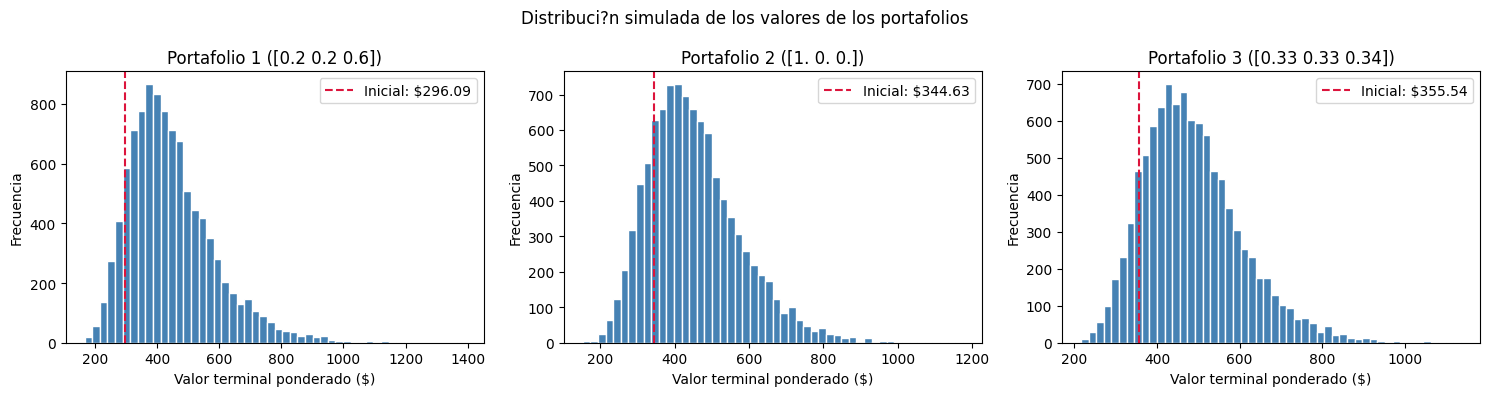

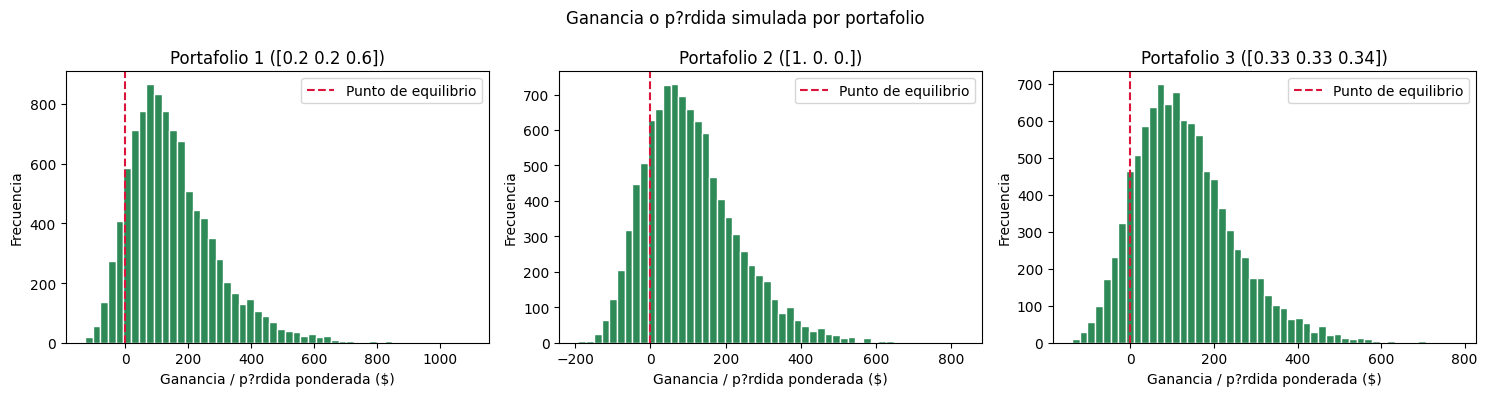

In [23]:


fig, axes = plt.subplots(1, len(Pesos), figsize=(15, 4), squeeze=False)
for i, ax in enumerate(axes[0]):
    ax.hist(ST_portafolios[i], bins=50, color="steelblue", edgecolor="white")
    ax.axvline(S0_portafolios[i], color="crimson", linestyle="--", label=f"Inicial: ${S0_portafolios[i]:,.2f}")
    ax.set(title=f"Portafolio {i + 1} ({Pesos[i]})", xlabel="Valor terminal ponderado ($)", ylabel="Frecuencia")
    ax.legend()
fig.suptitle("Distribuci?n simulada de los valores de los portafolios")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(Pesos), figsize=(15, 4), squeeze=False)
for i, ax in enumerate(axes[0]):
    ax.hist(resultado_portafolios[i], bins=50, color="seagreen", edgecolor="white")
    ax.axvline(0, color="crimson", linestyle="--", label="Punto de equilibrio")
    ax.set(title=f"Portafolio {i + 1} ({Pesos[i]})", xlabel="Ganancia / p?rdida ponderada ($)", ylabel="Frecuencia")
    ax.legend()
fig.suptitle("Ganancia o p?rdida simulada por portafolio")
fig.tight_layout()
plt.show()

### 2.9 VaR y CVaR al 95%

El riesgo se calcula sobre `resultado_portafolios`, es decir, la ganancia o pérdida en dólares de cada simulación. Se define `P5` como el percentil 5% de esa serie: `VaR 95% = -P5` y `CVaR 95% = -promedio de las pérdidas en el peor 5%`. Así, VaR y CVaR positivos representan pérdidas; si salen negativos, incluso el umbral o promedio de la cola representa una ganancia. Cada gráfica usa exactamente los mismos resultados del portafolio y señala sus cuartiles, media, P5 y CVaR.

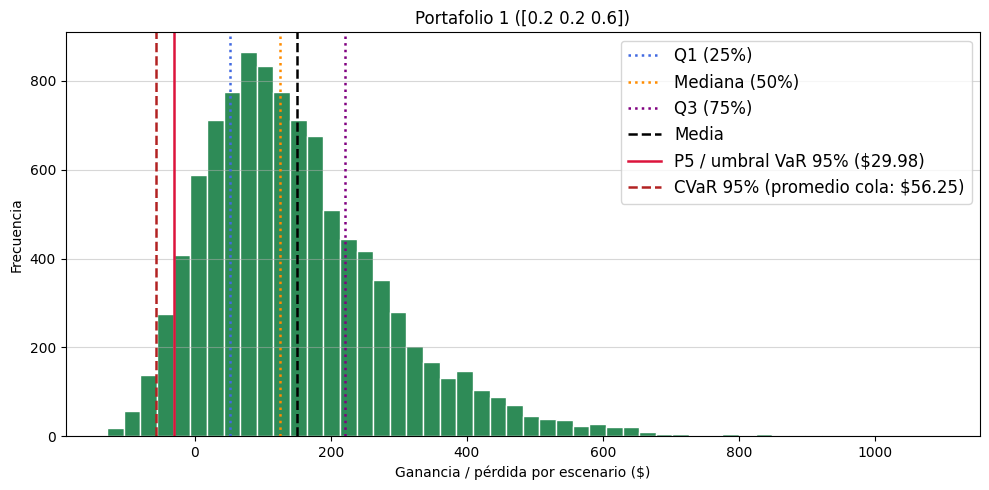

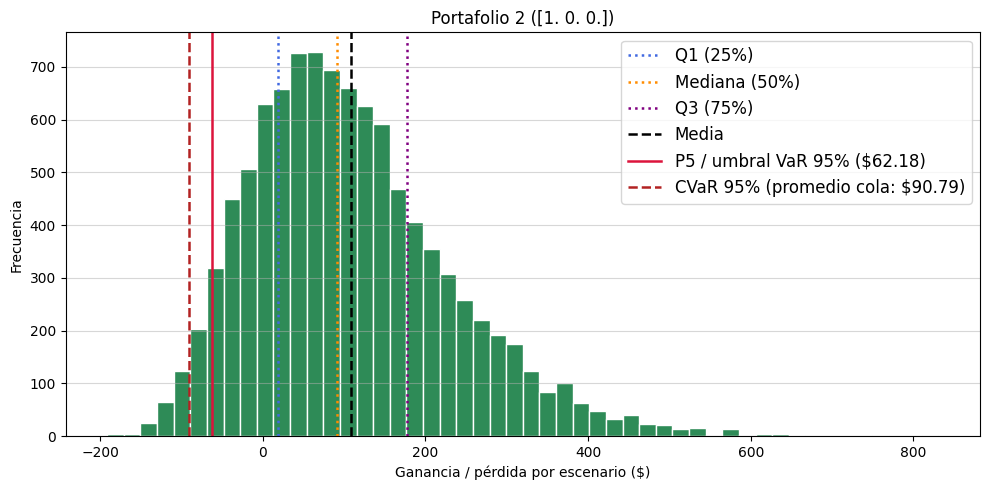

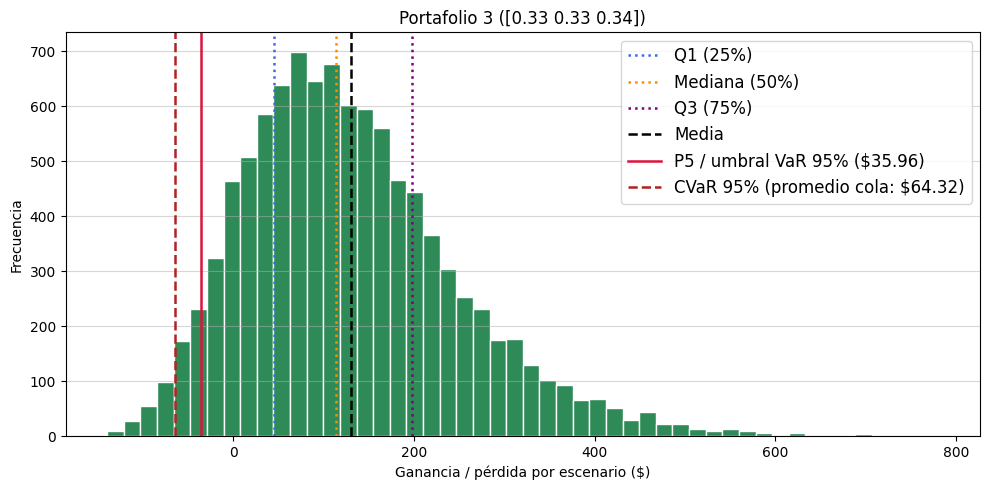

,Portafolio,VaR 95% ($),CVaR 95% ($)
0,Portafolio 1,$29.98,$56.25
1,Portafolio 2,$62.18,$90.79
2,Portafolio 3,$35.96,$64.32


In [24]:
resultados_riesgo = []

for i, pnl in enumerate(resultado_portafolios):
    p05, q1, mediana, q3 = np.quantile(pnl, [0.05, 0.25, 0.50, 0.75])
    media_pnl = np.mean(pnl)
    media_cola_pnl = np.mean(pnl[pnl <= p05])
    var95 = -p05
    cvar95 = -media_cola_pnl

    resultados_riesgo.append({
        'Portafolio': f'Portafolio {i + 1}',
        'VaR 95% ($)': var95,
        'CVaR 95% ($)': cvar95
    })

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(pnl, bins=50, color='seagreen', edgecolor='white')
    lineas = [
        (q1, 'Q1 (25%)', 'royalblue', ':'),
        (mediana, 'Mediana (50%)', 'darkorange', ':'),
        (q3, 'Q3 (75%)', 'purple', ':'),
        (media_pnl, 'Media', 'black', '--'),
        (p05, f'P5 / umbral VaR 95% (${var95:,.2f})', 'crimson', '-'),
        (media_cola_pnl, f'CVaR 95% (promedio cola: ${cvar95:,.2f})', 'firebrick', '--')
    ]
    for valor, etiqueta, color, estilo in lineas:
        ax.axvline(valor, color=color, linestyle=estilo, linewidth=1.8, label=etiqueta)

    ax.set(
        title=f'Portafolio {i + 1} ({Pesos[i]})',
        xlabel='Ganancia / pérdida por escenario ($)',
        ylabel='Frecuencia'
    )
    ax.legend(fontsize=12)
    ax.grid(axis='y', alpha=0.50)
    fig.tight_layout()
    plt.show()

tabla_riesgo = pd.DataFrame(resultados_riesgo)
display(tabla_riesgo.style.format({'VaR 95% ($)': '${:,.2f}', 'CVaR 95% ($)': '${:,.2f}'}))

La moda, media y mediana no son las mismas ppor lo tanto no son distribuciones normales.